# 02 · Análise exploratória (EDA)
[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jessicapmartins/previsao-faltas-consultas/blob/main/notebooks/02_eda.ipynb)

Foco: **o que diferencia quem falta de quem comparece?** Em todos os gráficos a pergunta é a mesma: a taxa de falta muda?

In [1]:
# Funções de apoio do projeto (mesma carga, mesmas variáveis e mesmo modelo em todos os notebooks)
import os, sys, urllib.request
try:
    import google.colab
    urllib.request.urlretrieve('https://raw.githubusercontent.com/jessicapmartins/previsao-faltas-consultas/main/src/apoio.py', '/content/apoio.py')
    sys.path.insert(0, '/content')
except ModuleNotFoundError:
    sys.path.insert(0, '../src')
import apoio, pandas as pd, numpy as np

con, DADOS, CSV = apoio.conectar()

def q(sql):
    """Roda uma consulta SQL no banco de consultas e devolve um DataFrame."""
    return pd.read_sql(sql, con)

apoio.garantir(con, CSV)
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style='whitegrid')

## 1. Base analítica
Uma linha por consulta, juntando as 3 tabelas e criando em SQL as variáveis que o modelo vai usar: antecedência, dia da semana, consultas e faltas **anteriores** e quantas consultas o paciente tem no mesmo dia. Os registros com erro (idade negativa ou acima de 100, consulta antes do agendamento) ficam de fora.

In [2]:
print(apoio.BASE_SQL)
apoio.criar_base_modelo(con)
base = q('SELECT * FROM base_modelo')
print(f'{len(base):,} consultas na base analítica (de {q("SELECT COUNT(*) n FROM consultas")["n"][0]:,} na original)')
base.head()


CREATE TABLE base_modelo AS
WITH c AS (
    SELECT c.consulta_id, c.paciente_id, c.data_agendamento, c.data_consulta, c.idade,
           c.sms_recebido, c.faltou, b.bairro,
           p.genero, p.bolsa_familia, p.hipertensao, p.diabetes, p.alcoolismo, p.deficiencia,
           CAST(julianday(c.data_consulta) - julianday(date(c.data_agendamento)) AS INTEGER) AS antecedencia_dias,
           CAST(strftime('%w', c.data_consulta) AS INTEGER)                              AS dia_semana
    FROM consultas c
    JOIN pacientes p ON p.paciente_id = c.paciente_id
    JOIN bairros   b ON b.bairro_id   = c.bairro_id
)
SELECT c.*,
       COUNT(*)     OVER hist                                        AS consultas_anteriores,
       COALESCE(SUM(faltou) OVER hist, 0)                            AS faltas_anteriores,
       COUNT(*)     OVER (PARTITION BY paciente_id, data_consulta)   AS consultas_no_dia
FROM c
WHERE idade BETWEEN 0 AND 100          -- remove idade -1 e idades implausíveis
  AND antec

,consulta_id,paciente_id,data_agendamento,data_consulta,idade,sms_recebido,faltou,bairro,genero,bolsa_familia,hipertensao,diabetes,alcoolismo,deficiencia,antecedencia_dias,dia_semana,consultas_anteriores,faltas_anteriores,consultas_no_dia
0,5751990,39217,2016-05-31 10:56:41,2016-06-03,44,0,0,PRAIA DO SUÁ,F,0,0,0,0,0,3,5,0,0,1
1,5760144,43741,2016-06-01 14:22:58,2016-06-01,39,0,0,MARIA ORTIZ,M,0,0,1,0,0,0,3,0,0,1
2,5712759,93779,2016-05-18 09:12:29,2016-05-18,33,0,0,CENTRO,F,0,0,0,0,0,0,3,0,0,1
3,5637648,141724,2016-04-29 07:13:36,2016-05-02,12,0,0,FORTE SÃO JOÃO,M,0,0,0,0,0,3,1,0,0,1
4,5637728,537615,2016-04-29 07:19:57,2016-05-06,14,1,0,FORTE SÃO JOÃO,F,0,0,0,0,0,7,5,0,0,1


## 2. Qualidade e resumo

In [3]:
print('Valores faltantes:', int(base.isna().sum().sum()))
base[['idade', 'antecedencia_dias', 'consultas_anteriores', 'faltas_anteriores', 'consultas_no_dia', 'faltou']].describe().round(2)

Valores faltantes: 0


,idade,antecedencia_dias,consultas_anteriores,faltas_anteriores,consultas_no_dia,faltou
count,110514.00,110514.00,110514.00,110514.00,110514.00,110514.0
mean,37.08,10.18,1.18,0.18,1.19,0.2
std,23.10,15.26,3.80,0.61,0.52,0.4
min,0.00,0.00,0.00,0.00,1.00,0.0
25%,18.00,0.00,0.00,0.00,1.00,0.0
50%,37.00,4.00,0.00,0.00,1.00,0.0
75%,55.00,15.00,1.00,0.00,1.00,0.0
max,100.00,179.00,83.00,15.00,10.00,1.0


**O que aprendi:** a base analítica tem 110.514 consultas (13 removidas por erro) e nenhum valor faltante. A antecedência mediana é de 4 dias, 75% das consultas são marcadas com até 15 dias, e o máximo é 179 dias.

## 3. Idade e antecedência: quem falta × quem comparece

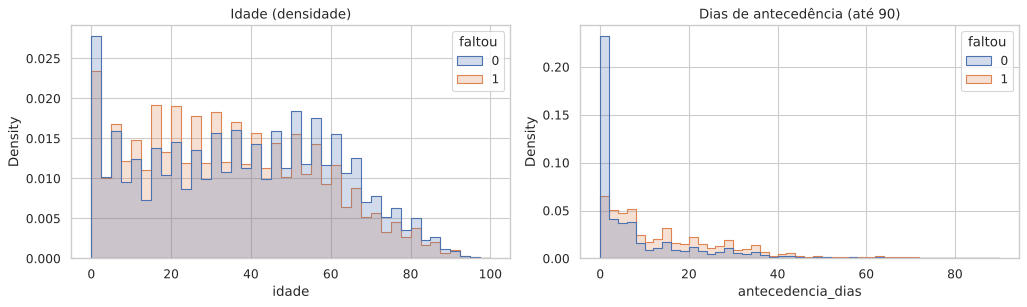

Mediana de antecedência (dias): {0: 2.0, 1: 11.0}


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=base, x='idade', hue='faltou', stat='density', common_norm=False, bins=40, element='step', ax=ax[0])
ax[0].set_title('Idade (densidade)')
sns.histplot(data=base[base['antecedencia_dias'] <= 90], x='antecedencia_dias', hue='faltou', stat='density',
             common_norm=False, bins=45, element='step', ax=ax[1])
ax[1].set_title('Dias de antecedência (até 90)')
plt.tight_layout(); plt.show()

print('Mediana de antecedência (dias):', base.groupby('faltou')['antecedencia_dias'].median().to_dict())

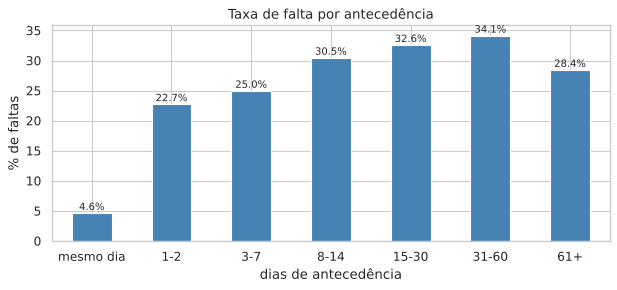

,mean,size
antecedencia_dias,,
mesmo dia,0.046,38560
1-2,0.227,11937
3-7,0.250,20245
8-14,0.305,12025
15-30,0.326,17370
31-60,0.341,8282
61+,0.284,2095


In [5]:
faixas = pd.cut(base['antecedencia_dias'], [-1, 0, 2, 7, 14, 30, 60, 200],
                labels=['mesmo dia', '1-2', '3-7', '8-14', '15-30', '31-60', '61+'])
taxa = base.groupby(faixas, observed=True)['faltou'].agg(['mean', 'size'])
ax = (100 * taxa['mean']).plot(kind='bar', figsize=(9, 3.5), color='steelblue', rot=0)
ax.set_ylabel('% de faltas'); ax.set_xlabel('dias de antecedência'); ax.set_title('Taxa de falta por antecedência')
for i, v in enumerate(100 * taxa['mean']):
    ax.text(i, v + 0.5, f'{v:.1f}%', ha='center', fontsize=9)
plt.show()
taxa.round(3)

**O que aprendi:** quem faltou agendou, em mediana, com **11 dias** de antecedência; quem compareceu, com **2 dias**. A taxa sobe de 4,6% no mesmo dia para 34,1% entre 31 e 60 dias e cai um pouco acima de 60 dias (28,4%, só 2.095 consultas). Quem falta também é mais jovem.

## 4. O efeito aparente do SMS
Na base inteira, quem recebeu SMS falta **mais**. O gráfico separa por antecedência para ver se é o SMS ou a antecedência.

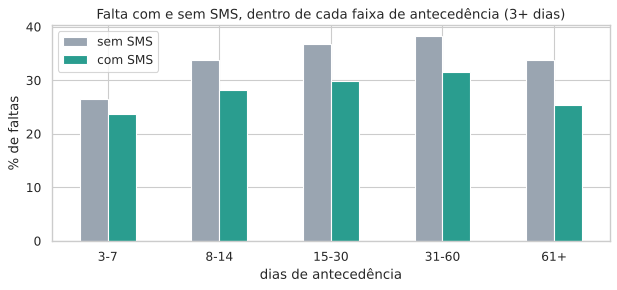

% de consultas com SMS por antecedência:
antecedencia_dias
mesmo dia     0.0
1-2           0.0
3-7          57.0
8-14         58.2
15-30        60.6
31-60        61.1
61+          64.5


In [6]:
sms = (base[base['antecedencia_dias'] >= 3]
       .assign(faixa=lambda d: pd.cut(d['antecedencia_dias'], [2, 7, 14, 30, 60, 200],
                                      labels=['3-7', '8-14', '15-30', '31-60', '61+']))
       .groupby(['faixa', 'sms_recebido'], observed=True)['faltou'].mean().unstack() * 100)
ax = sms.plot(kind='bar', figsize=(9, 3.5), rot=0, color=['#9aa5b1', '#2a9d8f'])
ax.set_ylabel('% de faltas'); ax.set_xlabel('dias de antecedência'); ax.legend(['sem SMS', 'com SMS'])
ax.set_title('Falta com e sem SMS, dentro de cada faixa de antecedência (3+ dias)')
plt.show()
print('% de consultas com SMS por antecedência:')
print((base.groupby(faixas, observed=True)['sms_recebido'].mean() * 100).round(1).to_string())

**O que aprendi:** nenhuma consulta com até 2 dias de antecedência recebeu SMS; a partir de 3 dias, entre 57% e 65% receberam. Dentro de cada faixa, o grupo com SMS falta de 2,8 a 8,4 pontos a menos (de 26,6% para 23,8% entre 3 e 7 dias; de 33,9% para 25,5% acima de 60). A associação é favorável, mas não é causal: é por isso que a regra de próxima melhor ação trata o efeito das ações como premissa.

## 5. Ao longo do tempo

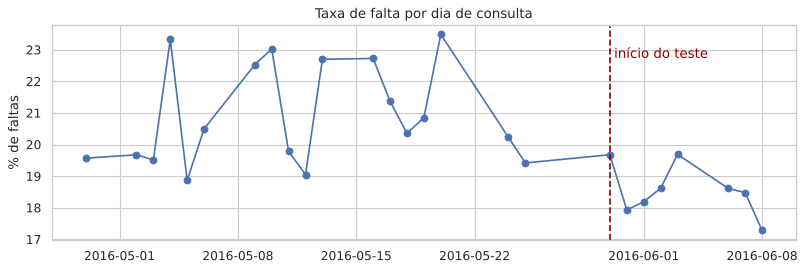

Taxa no treino x teste: {False: 0.21, True: 0.185}


In [7]:
dia = base.groupby('data_consulta').agg(consultas=('faltou', 'size'), taxa=('faltou', 'mean'))
dia = dia[dia['consultas'] > 100]                      # tira o sábado com só 39 consultas
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(pd.to_datetime(dia.index), 100 * dia['taxa'], marker='o')
ax.axvline(pd.Timestamp(apoio.DATA_CORTE), color='darkred', ls='--')
ax.text(pd.Timestamp(apoio.DATA_CORTE), ax.get_ylim()[1] * 0.97, ' início do teste', color='darkred', va='top')
ax.set_ylabel('% de faltas'); ax.set_title('Taxa de falta por dia de consulta')
plt.show()
print('Taxa no treino x teste:', base.groupby(base['data_consulta'] >= apoio.DATA_CORTE)['faltou'].mean().round(3).to_dict())

**O que aprendi:** a taxa diária oscila entre 17,3% e 23,5%, sem tendência clara. A semana de teste (30/05 a 08/06) teve menos faltas (18,5%) que o treino (21,0%). Um modelo treinado no período com mais faltas tende a superestimar um pouco o risco no teste.

## 6. Histórico do paciente, idade e outras relações

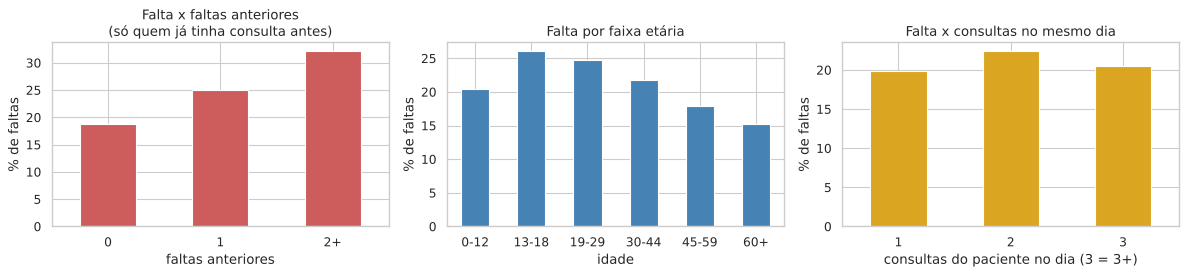

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
hist = pd.cut(base['faltas_anteriores'], [-1, 0, 1, 100], labels=['0', '1', '2+'])
(100 * base[base['consultas_anteriores'] > 0].groupby(hist, observed=True)['faltou'].mean()).plot(kind='bar', ax=ax[0], rot=0, color='indianred')
ax[0].set_title('Falta x faltas anteriores\n(só quem já tinha consulta antes)'); ax[0].set_xlabel('faltas anteriores')

idade = pd.cut(base['idade'], [-1, 12, 18, 29, 44, 59, 100], labels=['0-12', '13-18', '19-29', '30-44', '45-59', '60+'])
(100 * base.groupby(idade, observed=True)['faltou'].mean()).plot(kind='bar', ax=ax[1], rot=0, color='steelblue')
ax[1].set_title('Falta por faixa etária'); ax[1].set_xlabel('idade')

(100 * base.groupby(base['consultas_no_dia'].clip(upper=3))['faltou'].mean()).plot(kind='bar', ax=ax[2], rot=0, color='goldenrod')
ax[2].set_title('Falta x consultas no mesmo dia'); ax[2].set_xlabel('consultas do paciente no dia (3 = 3+)')
for a in ax: a.set_ylabel('% de faltas')
plt.tight_layout(); plt.show()

In [9]:
corr = base[['faltou', 'antecedencia_dias', 'faltas_anteriores', 'consultas_anteriores', 'consultas_no_dia', 'idade',
             'sms_recebido', 'bolsa_familia', 'hipertensao', 'diabetes', 'alcoolismo']].corr()['faltou'].drop('faltou')
corr.sort_values().round(3)

idade                  -0.060
hipertensao            -0.036
consultas_anteriores   -0.021
diabetes               -0.015
alcoolismo             -0.000
consultas_no_dia        0.011
bolsa_familia           0.029
faltas_anteriores       0.079
sms_recebido            0.127
antecedencia_dias       0.186
Name: faltou, dtype: float64

**O que aprendi:** entre pacientes que já tinham consulta antes, a falta vai de 18,8% (nenhuma falta anterior) a 25,0% (1 falta) e 32,1% (2 ou mais). Ter mais de uma consulta no mesmo dia quase não muda a taxa (19,9% com 1, 22,4% com 2). As correlações lineares são fracas: a maior é a da antecedência (0,19), e a do SMS (0,13) é, na verdade, efeito da antecedência.

## Principais achados
1. **Antecedência é o principal fator:** quem marca para o mesmo dia quase não falta (4,6%), e a falta passa de 30% a partir de 8 dias. Encurtar o prazo de agendamento, ou concentrar esforço nas consultas marcadas com antecedência, é a alavanca mais clara.
2. **Histórico e idade completam o perfil de risco:** quem já faltou 2 vezes falta 32%, e adolescentes e jovens adultos faltam mais que idosos.
3. **O efeito do SMS não pode ser medido com esta base:** o SMS foi enviado só a partir de 3 dias de antecedência e não ao acaso. A comparação dentro das faixas sugere um efeito favorável, mas só um teste A/B confirmaria.

## Gravar no Google Drive
Fecha o banco e força o Drive a gravar agora. Sem isso, o próximo notebook pode não enxergar as tabelas novas.

In [10]:
con.commit()
con.close()
try:
    from google.colab import drive
    drive.flush_and_unmount()
    print('Banco gravado no Google Drive.')
except ModuleNotFoundError:
    print('Fora do Colab: nada a sincronizar.')

Fora do Colab: nada a sincronizar.
